# Integrative Assignment on Week 02 Material — Northwind Fitness
## Python, NumPy, Pandas and Matplotlib — with verification

**ISM4543 | Applied Data Science | Fall 2026**

| | |
|---|---|
| **Due** | Monday, September 7, 2026, 11:59 PM |
| **Points** | 100, allocated by the six rubric components in the syllabus — Problem Framing 10, Technical Implementation 25, Verification Trail 15, Understanding 25, AI Usage Report 10, Critical Analysis 15. The Parts below are the shape of the work, not separate mark pots. |
| **Submit** | Three deliverables: this notebook (`.ipynb`), your **AI Usage Report** (the full Gemini conversation export *plus* your written account of it), and a **3–5 minute video walkthrough** (hard stop at five minutes). Submit the video as a **file upload on the Canvas assignment** or a **publicly accessible link in the Canvas submission comment** — never embedded in this notebook. **No video, or a link we cannot open, is −15 points.** The reflection section below is part of the notebook. |
| **Client brief** | Read `Week02-business-case.md` first — it is the engagement this assignment answers. |
| **AI policy** | AI assistance is **expected**, and documenting it is **required**. Explanations and reflections must be **your own words**. |
| **Late work** | 20% deduction up to 24 hours late. **After 24 hours, no credit.** |
| **Grade questions** | Raise any grading issue within **5 days** of the evaluation being posted. After that the evaluation stands. |

---

### Business context

**Northwind Fitness** operates four gyms across the Tampa Bay area. The operations
director, Marcus Bell, has exported the membership table and wants a picture of who
is leaving and why. He has been told by a vendor that he "needs machine learning."
He may or may not.

The export is real-world messy. Nobody warned you about that, and nobody will warn
you on the job either — **finding the problems is part of the assignment.** An
analysis built on this file without inspecting it first will produce numbers that
are confidently wrong.

### What this week is really about

Week 1 was the workflow. This week is the toolkit — NumPy, Pandas, Matplotlib —
and the discipline that has to come with it. Every part of this assignment can be
written by Gemini in seconds. Almost none of it can be *trusted* in seconds.

---

## Part 1: Load and inspect

### 1.1 Load the data

Do **not** start analysing. Load it, then look at it.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

DATA_URL = "https://raw.githubusercontent.com/prof-tcsmith/4543Fall26-DATA/main/data/week02/northwind_members.csv"

members = pd.read_csv(DATA_URL)

members.head()

,member_id,plan,region,monthly_fee_usd,months_active,avg_visits_per_month,support_tickets,churned
0,NW11192,Premium,Tampa,89.0,4,9.3,1,0
1,NW10971,Premium,Tampa,89.0,16,11.3,0,0
2,NW10038,Standard,Tampa,54.0,8,8.2,1,0
3,NW10961,Premium,Tampa,89.0,15,8.0,0,0
4,NW10935,Basic,St. Petersburg,29.0,16,3.7,2,0


### 1.2 The inspection ritual

Before any analysis, run the checks below and record what you find. Prompt Gemini
for the code if you like — but *you* decide what to check.

| Check                     | Command you used                                                      | What you found                                                                                                                                                            |
| ------------------------- | --------------------------------------------------------------------- | ------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| Shape                     | `members.shape`                                                       | `(1218, 8)` — 1,218 rows and 8 columns                                                                                                                                    |
| Column types              | `members.dtypes`                                                      | `member_id`, `plan`, and `region` are object; `monthly_fee_usd` and `avg_visits_per_month` are float; `months_active`, `support_tickets`, and `churned` are integer       |
| Missing values per column | `members.isna().sum()`                                                | `avg_visits_per_month` has 85 missing values; all other columns have 0 missing values                                                                                     |
| Duplicate rows            | `members.duplicated().sum()`                                          | 18 duplicate rows                                                                                                                                                         |
| Unique values in `region` | `members["region"].unique()`                                          | 8 values: `BRANDON`, `Brandon`, `CLEARWATER`, `Clearwater`, `ST. PETERSBURG`, `St. Petersburg`, `TAMPA`, `Tampa`. The same 4 regions appear with different capitalization |
| Unique values in `plan`   | `members["plan"].unique()`                                            | 3 plans: `Basic`, `Premium`, `Standard`                                                                                                                                   |
| Range of `months_active`  | `members["months_active"].min()` and `members["months_active"].max()` | Minimum = 1 month; Maximum = 50 months                                                                                                                                    |


In [ ]:
print("Shape:")
print(members.shape)

print("\nColumn types:")
print(members.dtypes)

print("\nMissing values:")
print(members.isna().sum())

print("\nDuplicate rows:")
print(members.duplicated().sum())

print("\nUnique regions:")
print(sorted(members["region"].dropna().unique()))

print("\nUnique plans:")
print(sorted(members["plan"].dropna().unique()))

print("\nMonths active range:")
print("Min:", members["months_active"].min())
print("Max:", members["months_active"].max())

Shape:
(1218, 8)

Column types:
member_id                object
plan                     object
region                   object
monthly_fee_usd         float64
months_active             int64
avg_visits_per_month    float64
support_tickets           int64
churned                   int64
dtype: object

Missing values:
member_id                0
plan                     0
region                   0
monthly_fee_usd          0
months_active            0
avg_visits_per_month    85
support_tickets          0
churned                  0
dtype: int64

Duplicate rows:
18

Unique regions:
['BRANDON', 'Brandon', 'CLEARWATER', 'Clearwater', 'ST. PETERSBURG', 'St. Petersburg', 'TAMPA', 'Tampa']

Unique plans:
['Basic', 'Premium', 'Standard']

Months active range:
Min: 1
Max: 50


### 1.3 What each problem would break

For each problem you found, name a **specific** analysis it would corrupt and say
how the wrong answer would look.

| Problem                                     | Analysis it breaks               | What the wrong answer looks like                                                                   |
| ------------------------------------------- | -------------------------------- | -------------------------------------------------------------------------------------------------- |
| 85 missing values in `avg_visits_per_month` | Average visit analysis           | The average would only use members with recorded visit values, so it may not represent the full membership base |
| 18 duplicate rows                           | Member counts and churn analysis | Some members would be counted twice, making totals and churn results inaccurate                    |
| Inconsistent capitalization in `region`     | Churn rate by region             | The same city would appear as separate groups, such as `TAMPA` and `Tampa`, instead of one region  |


---

## Part 2: Clean it

Fix all three problems. For each fix, **state the decision you made and why** —
these are judgment calls, not mechanical steps, and a different analyst could
defensibly choose otherwise.

In [ ]:
# Start from the raw data
clean = members.copy()

# Remove duplicate rows
clean = clean.drop_duplicates().copy()

# Standardize region capitalization
clean["region"] = clean["region"].str.strip().str.title()

# Fill missing visit values using median within each plan
plan_medians = clean.groupby("plan")["avg_visits_per_month"].transform("median")

clean["avg_visits_per_month"] = (
    clean["avg_visits_per_month"].fillna(plan_medians)
)

# Basic verification
print("Clean shape:", clean.shape)

print("\nMissing values:")
print(clean.isna().sum())

print("\nDuplicate rows:")
print(clean.duplicated().sum())

print("\nRegions:")
print(sorted(clean["region"].unique()))

# Final verification checks
assert clean.shape[0] == 1200
assert clean.duplicated().sum() == 0
assert clean.isna().sum().sum() == 0
assert clean["region"].nunique() == 4

print("\nAll cleaning checks passed.")

Clean shape: (1200, 8)

Missing values:
member_id               0
plan                    0
region                  0
monthly_fee_usd         0
months_active           0
avg_visits_per_month    0
support_tickets         0
churned                 0
dtype: int64

Duplicate rows:
0

Regions:
['Brandon', 'Clearwater', 'St. Petersburg', 'Tampa']

All cleaning checks passed.


**Your cleaning decisions:**

| Problem                                     | What you did                                               | Why, and what you gave up                                                                                                                                                                                         |
| ------------------------------------------- | ---------------------------------------------------------- | ----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| 18 duplicate rows                           | Removed exact duplicate rows with `drop_duplicates()`      | I treated the duplicates as repeated records because they were exactly the same. This avoids counting the same member twice, but there is a small chance that a duplicate could have been a real repeated record. |
| Inconsistent `region` capitalization        | Standardized all region names using `.str.title()`         | This combines values like `TAMPA` and `Tampa` into one region. I gave up the original capitalization, but the region meaning stays the same.                                                                      |
| 85 missing values in `avg_visits_per_month` | Filled missing values with the median visits for each plan | I used the plan median because visit behavior may be different across plan types. This keeps all members in the dataset, but the filled values are estimates and may reduce some real variation.                  |


---

## Part 3: NumPy

Use **NumPy** (not Pandas aggregations) for this part — the point is to know both.

Compute, from the cleaned data:

1. The mean and standard deviation of `avg_visits_per_month`
2. The 25th, 50th, and 75th percentiles of `months_active`
3. The share of members who visit more than one standard deviation above the mean

In [ ]:
# Convert cleaned columns to NumPy arrays
visits = clean["avg_visits_per_month"].to_numpy()
months = clean["months_active"].to_numpy()

# 1. Mean and standard deviation of monthly visits
mean_visits = np.mean(visits)
std_visits = np.std(visits)

# 2. 25th, 50th, and 75th percentiles of months active
percentiles = np.percentile(months, [25, 50, 75])

# 3. Share visiting more than one SD above the mean
threshold = mean_visits + std_visits
high_visit_share = np.mean(visits > threshold)

print(f"Mean visits per month: {mean_visits:.2f}")
print(f"Standard deviation: {std_visits:.2f}")

print(f"25th percentile months active: {percentiles[0]:.2f}")
print(f"50th percentile months active: {percentiles[1]:.2f}")
print(f"75th percentile months active: {percentiles[2]:.2f}")

print(f"One-SD-above-mean threshold: {threshold:.2f}")
print(f"Share above threshold: {high_visit_share:.2%}")

Mean visits per month: 7.74
Standard deviation: 3.00
25th percentile months active: 7.00
50th percentile months active: 11.00
75th percentile months active: 18.00
One-SD-above-mean threshold: 10.74
Share above threshold: 17.67%


**One sentence for Marcus** interpreting the third number — what does it tell him
about his membership base?

*Your answer here: About 17.67% of members visit more than one standard deviation above the average, showing that only a small group of members are much more active than most members.*

---

## Part 4: Pandas aggregation

### 4.1 The churn table

Build a single table showing, **for each plan tier**: member count, churn rate,
average tenure, and average visits per month. Sort by churn rate, worst first.

In [ ]:
plan_summary = (
    clean.groupby("plan")
    .agg(
        member_count=("member_id", "count"),
        churn_rate=("churned", "mean"),
        average_tenure=("months_active", "mean"),
        average_visits=("avg_visits_per_month", "mean")
    )
)

# Convert churn rate to percentage
plan_summary["churn_rate"] = plan_summary["churn_rate"] * 100

# Worst churn first
plan_summary = plan_summary.sort_values(
    "churn_rate",
    ascending=False
)

display(plan_summary.round(2))

,member_count,churn_rate,average_tenure,average_visits
plan,,,,
Basic,576,8.85,13.11,6.29
Standard,445,6.52,13.28,8.41
Premium,179,1.68,12.79,10.74


### 4.2 Read the table

What is the relationship between plan tier and churn? Give the finding **and** one
alternative explanation that the data cannot rule out.

*Your answer here: Churn is highest for Basic members at 8.85%, followed by Standard at 6.52%, while Premium has the lowest churn at 1.68%. This suggests higher plan tiers are linked with lower churn, but the plan itself may not be the cause. Premium members also visit more often, so higher engagement could help explain why they churn less*

---

## Part 5: Visualization

Produce **two** charts:

1. One that shows the churn story clearly
2. One that shows something you found surprising

For each: a real title, labelled axes, and one sentence on the decision it supports.

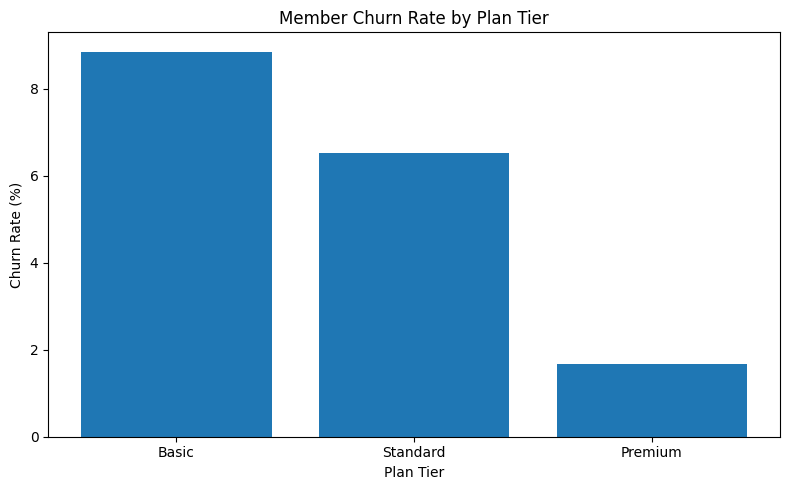

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    plan_summary.index,
    plan_summary["churn_rate"]
)

plt.title("Member Churn Rate by Plan Tier")
plt.xlabel("Plan Tier")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()

*This chart shows that Basic members have the highest churn rate, so Marcus should focus retention efforts on Basic members first.*

,member_count,churn_rate
support_tickets,,
0,579,5.18
1,434,8.29
2,145,8.28
3,32,12.50
4,9,11.11
5,1,0.00


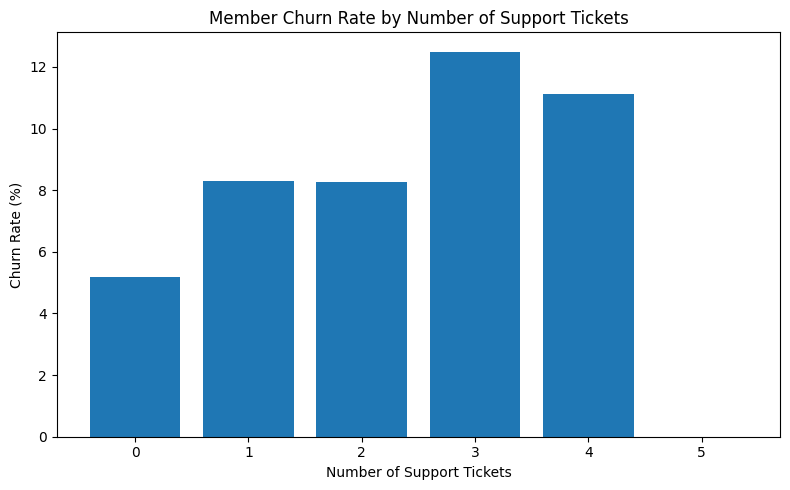

In [ ]:
ticket_summary = (
    clean.groupby("support_tickets")
    .agg(
        member_count=("member_id", "count"),
        churn_rate=("churned", "mean")
    )
)

ticket_summary["churn_rate"] = ticket_summary["churn_rate"] * 100

display(ticket_summary.round(2))

plt.figure(figsize=(8, 5))

plt.bar(
    ticket_summary.index.astype(str),
    ticket_summary["churn_rate"]
)

plt.title("Member Churn Rate by Number of Support Tickets")
plt.xlabel("Number of Support Tickets")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()

*I was surprised that members with 3 or 4 support tickets had the highest churn rates, so Marcus should review repeated support problems and follow up with these members earlier.*

---

## Part 6: Spot the error

Gemini was asked:

> *"What percentage of members in each region have churned?"*

It produced this. It runs. The output is wrong.

In [ ]:
# AI-GENERATED CODE — DO NOT TRUST IT
region_churn = members.groupby("region")["churned"].sum() / len(members) * 100
print(region_churn.round(1))

region
BRANDON           0.0
Brandon           1.1
CLEARWATER        0.1
Clearwater        1.2
ST. PETERSBURG    0.1
St. Petersburg    2.5
TAMPA             0.1
Tampa             1.9
Name: churned, dtype: float64


### 6.1 What is wrong

There are **two** independent problems here — one in the arithmetic, one in the
data it was pointed at.

| # | Problem                              | Why it produces a wrong answer                                                                                                       |
| - | ------------------------------------ | ------------------------------------------------------------------------------------------------------------------------------------ |
| 1 | The code divides by `len(members)`   | It divides each region’s churners by all members, instead of the number of members in that region.                                   |
| 2 | The code uses the raw `members` data | The raw data still has duplicates and different capitalization, so places like `TAMPA` and `Tampa` are treated as different regions. |


In [ ]:
region_churn = (
    clean.groupby("region")["churned"].mean() * 100
)

region_churn = region_churn.sort_values(ascending=False)

print(region_churn.round(1))

region
St. Petersburg    9.5
Brandon           7.5
Clearwater        6.0
Tampa             5.4
Name: churned, dtype: float64


### 6.2 The general lesson

You have now seen two "spot the error" exercises across two weeks. Both bugs were
silent. Write 3–4 sentences on what these two cases have in common, and what habit
you are going to adopt because of them.

*Your answer here: Both errors were hard to notice because the code still ran without an error message. I learned that code can run correctly but still give the wrong answer. I need to check the data, the denominator, and whether the result makes sense before trusting it. From now on, I will always do a few simple checks after running AI-generated code.*

---

## Part 7: Reflection and AI Usage Report

Answer these in **your own words**. AI-generated reflections receive zero credit —
they are easy to spot, because they are fluent and say nothing specific.

> **Why this section exists.** You are required to use AI in this course, and using
> it responsibly is a professional skill in its own right — one that has to be
> practised, not assumed. That skill starts here: stating plainly what you asked,
> what came back, how you checked it, and what you changed when the check failed.
> An engineer who cannot account for where their code came from cannot be trusted
> with it, and neither can an analyst. Recounting your own process is how you learn
> to notice it.

### 6.1 Prompt evolution log

Show how at least one of your prompts evolved. What did you ask first, what was
wrong with what you got back, **how did you detect that it was wrong**, and how did
you fix the prompt?

```
Attempt 1: ...
   Result: ...
   How I checked it: ...
   Problem: ...
Attempt 2: ...
   Result: ...
   How I checked it: ...
   Problem: ...
Attempt 3: ...
   Result: ...
   How I checked it: ...
```

*Your log here:*
```
Attempt 1: "Step by step to finish this assignment."
   Result: ChatGPT gave me code and instructions for each part of the assignment.
   How I checked it: I ran the code in the notebook and checked the shape, missing values, duplicates, and regions.
   Problem: I understood the code, but I was not sure where some verification code, like the assert statements, should go.

Attempt 2: "Where to put this assert code?"
   Result: ChatGPT explained that the assert statements should go at the end of the cleaning cell after the cleaning steps.
   How I checked it: I ran the cell and got "All cleaning checks passed."
   Problem: I still needed help understanding the purpose of the wrong AI-generated code in Part 6.

Attempt 3: "So just run this?"
   Result: ChatGPT explained that I should run the wrong code first, look at the wrong output, and then fix it.
   How I checked it: The output showed regions like TAMPA and Tampa as separate groups. I then used the cleaned data and got only four regions.
```
### 6.2 Where the AI struggled

Describe one specific point where the AI gave you something wrong, incomplete, or
misleading. What did you have to know already in order to catch it?

*Your answer here: One place where AI could have been misleading was Part 6. The original code ran without any Python error, so it looked correct at first. I had to understand that the denominator should be the number of members inside each region, not the total number of members in the whole dataset. I also had to notice that the code used the raw members data instead of the cleaned clean data.*

### 6.3 What was harder or easier than expected

*Your answer here: Cleaning the data was easier than I expected because Pandas has simple functions for duplicates and missing values. The harder part was checking whether a calculation actually answered the business question. I learned that debugging is not only fixing code errors. Sometimes the code runs correctly, but the logic is still wrong.*

### 6.4 Confidence self-assessment

Rate 1 (lost) to 5 (could teach it), and be honest — this is not graded on the
number, it is graded on whether the reflection that follows is candid.

| Topic                          | 1–5 | What would move this up one point?                             |
| ------------------------------ | --: | -------------------------------------------------------------- |
| Pandas inspection and cleaning |   4 | More practice cleaning different types of messy data           |
| NumPy calculations             |   3 | More practice with arrays, percentiles, and standard deviation |
| Groupby and aggregation        |   4 | More practice with different groupby questions                 |
| Matplotlib charts              |   3 | More practice choosing the best chart for a business question  |
| Checking and debugging AI code |   4 | More practice finding logic errors without help                |

### 6.5 AI Usage Report

**Required.** Name every AI tool you used, what you used each one for, and attach
the full conversation export as a separate file. Then account for the work: which
outputs you accepted as-is, which you checked and how, which you corrected, and
which you rejected outright. "I used Gemini for the code" is not a report.

*Your report here:I used ChatGPT to help me understand the assignment, write some of the Python code, and explain errors when I was confused. I first asked for a step-by-step guide for the assignment. I also asked where to place the verification assert statements and how to complete the "spot the error" section.I accepted the basic data-loading and inspection code after checking that the shape, columns, and data types matched the dataset.*

*I couldn't accept every answer without checking it. I ran the code in the notebook and checked the outputs. For the cleaning section, I checked that the data changed from 1,218 rows to 1,200 rows, had zero duplicate rows, zero missing values, and four unique regions. I also used the assert statements to confirm these results.*

*In Part 6, I first ran the AI-generated code that was intentionally wrong. I saw that values such as TAMPA and Tampa appeared as different regions. I also checked the calculation and noticed that it divided by the total number of members instead of the number of members in each region. I corrected the code by using the cleaned dataset and calculating the mean of the churned column for each region.*

*One thing I also changed was the original region churn calculation. Even though the code ran successfully, the result did not answer the question correctly. This showed me why I need to check AI-generated code instead of only checking whether it runs.*

---

## Before you submit

- [ ] **Kernel -> Restart & Run All**, top to bottom. Save the file *after* it has
      run, so your outputs are in what you upload.
- [ ] **One exception:** the AI-generated cell in the *Spot the error* section may
      stop the run -- that cell is **meant** to fail, and that is the point of the
      exercise. Run your corrected version by hand afterwards so its output is
      saved, then save the notebook. Nothing else should raise.
- [ ] Every *your answer here* prompt is filled in, in **your own words**.
- [ ] Your **AI Usage Report** is complete -- the prompting, the results, the
      checking, the re-prompting, and one thing you rejected -- **plus the full
      conversation export attached as a separate file.** The written account alone
      does not satisfy it.
- [ ] File named **`LastName_FirstName_Week02.ipynb`**.
- [ ] Video recorded and submitted -- **file upload on the Canvas assignment, or a
      publicly accessible link in the Canvas submission comment**. Not in this
      notebook. Test the link signed out: no video, or a link we cannot open, is
      **-15 points**.